# 02. Ingeniería de Características (Sin Fuga de Datos)

**Proyecto:** PSet #3 — Experimentación y Selección del Modelo con MLflow  
**Objetivo:** Diseñar y validar empíricamente las *features* derivadas que operan el **día 15 del mes $t$**, verificar ausencia total de *data leakage* y comparar la codificación de variables categóricas (`OneHotEncoder` vs. `OrdinalEncoder`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.datos import (
    COLUMNAS_FUGA,
    dividir_train_test,
    preparar_universo_nowcasting,
)
from src.pipeline import (
    CATEGORICAS,
    COLUMNAS_MODELO,
    NUMERICAS,
    OBJETIVO,
    YA_LISTAS,
    agregar_features,
    construir_preparacion,
)

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

df_univ = preparar_universo_nowcasting()
df_feat = agregar_features(df_univ)
train_df, test_df = dividir_train_test(df_feat)

print(f"Train (2016-01 a 2024-12): {len(train_df)} filas")
print(f"Test hold-out (2025-01 a 2026-06, NO TOCAR aquí): {len(test_df)} filas")

Train (2016-01 a 2024-12): 4907 filas
Test hold-out (2025-01 a 2026-06, NO TOCAR aquí): 828 filas


## 1. Definición del momento de la predicción, puente hacia el VAB del IMAEC y auditoría anti-fuga

En el flujo de coyuntura económica (PSet #1 y #2), el modelo ejecuta el *nowcast* el **día 15 posterior al cierre del mes fiscal $t$** (`TIPO_CORTE = 'temprano_15d'`).
- **Transformación Ventas F104 → Valor Agregado Bruto (VAB) del IMAEC (Feedback PSet #1):** En la metodología de Cuentas Nacionales Trimestrales y Mensuales del BCE, los coeficientes técnicos de consumo intermedio ($c_i = CI_i / VBP_i$) son estables en el corto plazo mensual, por lo que el índice de volumen encadenado del Valor Agregado Bruto de la rama $i$ ($\text{VAB}_{i,t} = (1 - c_i) VBP_{i,t}$) evoluciona proporcionalmente a las ventas reales deflactadas con el índice de precios específico de la rama ($\Delta\% \text{VAB}_{i,t} \approx \Delta\% \text{VentasReales}_{i,t}$). Así, `ventas_temprano_ipc_real` (ventas tempranas deflactadas con `INDICE_PRECIO_REAL`) y `proyeccion_cobertura_12m` (extrapolación a cierre mensual corregida por la cobertura histórica `[t-12, t-1]`), comparadas contra `ventas_definitivo_real_lag12_musd` ($t-12$), permiten estimar directamente la variación interanual del VAB sectorial y del agregado nacional del IMAEC Flash ($\widehat{g}_t^{(15\text{d})}$).
- **Información disponible en el día 15 (sin fuga):** `VENTAS_NOMINALES_USD`, `NUM_DECLARANTES`, clasificación CIIU, `INDICE_PRECIO_REAL`, rezagos tempranos (`t-1`, `t-12`), rezagos definitivos cerrados (`t-2`, `t-12`) y `RATIO_REPRESENTATIVIDAD_HIST_12M` sobre `[t-12, t-1]`.
- **Información prohibida (fuga del futuro):** el cierre definitivo del mes $t$ y cualquier razón contemporánea (`RATIO_REPRESENTATIVIDAD_CORTE`, `RATIO_CORTE_VS_HIST_12M`, `FLAG_TEMPRANO_MAYOR_DEFINITIVO`).

In [2]:
presentes_fuga = [c for c in COLUMNAS_FUGA if c in train_df.columns]
assert len(presentes_fuga) == 0, f"Fuga detectada: {presentes_fuga}"
print("[OK] Auditoría anti-fuga superada: 0 columnas prohibidas en train/model.")
print("Total columnas de entrada del modelo:", len(COLUMNAS_MODELO))
print(" - Numéricas:", len(NUMERICAS))
print(" - Categóricas:", len(CATEGORICAS))
print(" - Ya listas:", len(YA_LISTAS))

[OK] Auditoría anti-fuga superada: 0 columnas prohibidas en train/model.
Total columnas de entrada del modelo: 22
 - Numéricas: 14
 - Categóricas: 3
 - Ya listas: 5


## 2. Evidencia cuantitativa de las features derivadas (exclusivamente sobre `train`)

Se evalúan todas las features derivadas construidas en `src/pipeline.py` sobre el conjunto de entrenamiento (`2016-01` a `2024-12`), sin usar jamás la partición `test`.

,feature,n_validos,pearson_target,spearman_target,media,mediana
2,proyeccion_cobertura_12m,4904,0.9995,0.9930,357.6948,158.2471
0,ventas_temprano_ipc_real,4907,0.9685,0.9506,127.7624,43.2873
4,ratio_temprano_vs_lag1,4871,0.0176,0.1080,1.0930,1.0152
7,es_diciembre,4907,0.0573,0.1070,0.0834,0.0000
3,ratio_temprano_vs_lag12,4872,-0.0045,0.0870,1.0798,1.0322
1,inflacion_sectorial_12m_lag1,4861,-0.0196,0.0527,2.0815,0.6381
8,impulso_declarantes,4901,0.0266,0.0503,1.0271,1.0275
5,mes_sin,4907,-0.0105,-0.0310,-0.0001,-0.0000
6,mes_cos,4907,0.0130,0.0200,-0.0002,-0.0000



Impacto de las features derivadas en TimeSeriesSplit (5 pliegues sobre train):


,modelo,mae_cv_crudas,std_cv_crudas,mae_cv_features_derivadas,std_cv_features_derivadas,mejora_pct
0,Ridge,54.125,15.453,16.844,1.879,68.88
1,HistGradientBoosting,52.846,27.804,31.329,12.633,40.72


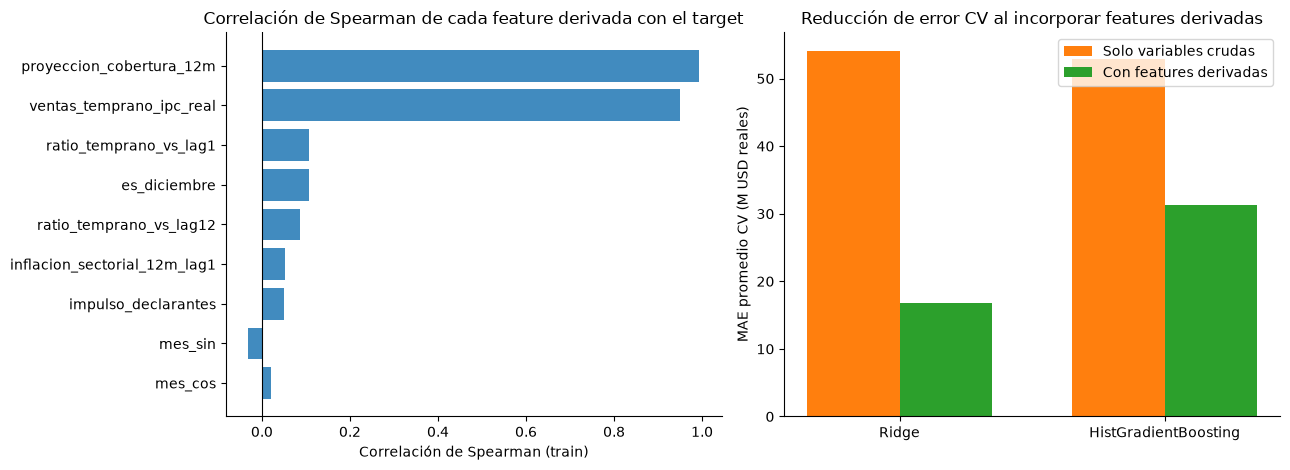

In [3]:
features_nuevas = [
    "ventas_temprano_ipc_real",
    "inflacion_sectorial_12m_lag1",
    "proyeccion_cobertura_12m",
    "ratio_temprano_vs_lag12",
    "ratio_temprano_vs_lag1",
    "mes_sin",
    "mes_cos",
    "es_diciembre",
    "impulso_declarantes",
]

evidencia_rows = []
for col in features_nuevas:
    s = train_df[col]
    y_tr = train_df[OBJETIVO]
    evidencia_rows.append({
        "feature": col,
        "n_validos": int(s.notna().sum()),
        "pearson_target": round(float(s.corr(y_tr, method="pearson")), 4),
        "spearman_target": round(float(s.corr(y_tr, method="spearman")), 4),
        "media": round(float(s.mean()), 4),
        "mediana": round(float(s.median()), 4),
    })
df_evidencia = pd.DataFrame(evidencia_rows).sort_values("spearman_target", key=abs, ascending=False)
display(df_evidencia)

# Ablación temporal (TimeSeriesSplit=5) comparando solo variables crudas base vs set completo con features derivadas
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cols_crudas_num = ["VENTAS_NOMINALES_USD", "NUM_DECLARANTES", "INDICE_PRECIO_REAL"]
prep_crudo = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), cols_crudas_num),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
])
prep_completo = construir_preparacion("onehot")

tscv = TimeSeriesSplit(n_splits=5)
X_tr_crudo = train_df[cols_crudas_num + CATEGORICAS]
X_tr_comp = train_df[COLUMNAS_MODELO]
y_tr = train_df[OBJETIVO]

ablacion = []
for nombre_mod, mod in [
    ("Ridge", Ridge(alpha=1.0)),
    ("HistGradientBoosting", HistGradientBoostingRegressor(random_state=42)),
]:
    mae_crudo = -cross_val_score(
        Pipeline([("p", prep_crudo), ("m", mod)]),
        X_tr_crudo, y_tr, cv=tscv, scoring="neg_mean_absolute_error"
    )
    mae_comp = -cross_val_score(
        Pipeline([("p", prep_completo), ("m", mod)]),
        X_tr_comp, y_tr, cv=tscv, scoring="neg_mean_absolute_error"
    )
    ablacion.append({
        "modelo": nombre_mod,
        "mae_cv_crudas": round(float(mae_crudo.mean()), 3),
        "std_cv_crudas": round(float(mae_crudo.std()), 3),
        "mae_cv_features_derivadas": round(float(mae_comp.mean()), 3),
        "std_cv_features_derivadas": round(float(mae_comp.std()), 3),
        "mejora_pct": round(float((mae_crudo.mean() - mae_comp.mean()) / mae_crudo.mean() * 100), 2),
    })

df_ablacion = pd.DataFrame(ablacion)
print("\nImpacto de las features derivadas en TimeSeriesSplit (5 pliegues sobre train):")
display(df_ablacion)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
df_ev_plot = df_evidencia.sort_values("spearman_target", key=abs, ascending=True)
axes[0].barh(df_ev_plot["feature"], df_ev_plot["spearman_target"], color="#1f77b4", alpha=0.85)
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set_title("Correlación de Spearman de cada feature derivada con el target")
axes[0].set_xlabel("Correlación de Spearman (train)")

x_idx = np.arange(len(df_ablacion))
w = 0.35
axes[1].bar(x_idx - w/2, df_ablacion["mae_cv_crudas"], width=w, label="Solo variables crudas", color="#ff7f0e")
axes[1].bar(x_idx + w/2, df_ablacion["mae_cv_features_derivadas"], width=w, label="Con features derivadas", color="#2ca02c")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(df_ablacion["modelo"])
axes[1].set_ylabel("MAE promedio CV (M USD reales)")
axes[1].set_title("Reducción de error CV al incorporar features derivadas")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "02_evidencia_features.png", dpi=180, bbox_inches="tight")
plt.show()

### Justificación por grupo de features (disponibilidad en el día 15)

| Feature derivada | Evidencia (hallazgo / señal) | Disponibilidad al momento de inferencia (día 15 de $t$) |
|---|---|---|
| `ventas_temprano_ipc_real` & `inflacion_sectorial_12m_lag1` | Deflacta las ventas tempranas al mismo poder adquisitivo real del target (`INDICE_PRECIO_REAL`) y añade la inflación sectorial interanual rezagada ($t-1$ vs $t-13$). | `VENTAS_NOMINALES_USD` se observa al corte del día 15; `INDICE_PRECIO_REAL` se publica en la primera semana siguiente al mes $t$, y los rezagos usan $t-1$ y $t-13$. |
| `proyeccion_cobertura_12m` | Captura el estimador estructural multiplicativo `ventas_temprano / cobertura_historica_12m` acotada en `[0.05, 1.0]` (correlación más alta con el target). | `RATIO_REPRESENTATIVIDAD_HIST_12M` usa exclusivamente la ventana pasada `[t-12, t-1]` (cero fuga del mes $t$). |
| `ratio_temprano_vs_lag12` & `ratio_temprano_vs_lag1` | Miden la aceleración interanual y mensual real observada en el propio corte temprano de la rama. | Se calculan únicamente con `ventas_temprano_ipc_real` en $t$ y sus rezagos tempranos reales en $t-1$ y $t-12$. |
| `mes_sin`, `mes_cos`, `es_diciembre` | Capturan la estacionalidad cíclica sin salto artificial entre mes 12 y mes 1, más el pico comercial de diciembre. | El mes fiscal $t$ se conoce determinísticamente antes de ejecutar la predicción. |
| `impulso_declarantes` | Detecta si en el corte temprano del mes $t$ declararon más o menos contribuyentes que su media móvil histórica `[t-12, t-1]`, anticipando variaciones en la cobertura del corte. | `NUM_DECLARANTES` se registra el día 15 y la media móvil excluye el mes $t$. |

## 3. Comparación de codificación categórica: `OneHotEncoder` vs. `OrdinalEncoder`

Las variables categóricas del problema son `CODIGO_INDUSTRIA` (46 ramas CIIU), `SECTOR_MACRO` (8 macro-sectores) y `SECTOR_ECONOMICO` (3 grandes sectores). Se evalúa el impacto de `OneHotEncoder(handle_unknown="ignore", sparse_output=False)` frente a `OrdinalEncoder` en un modelo lineal (`Ridge`) y un ensamblaje de árboles (`HistGradientBoostingRegressor`) sobre `TimeSeriesSplit(n_splits=5)`.

,codificacion,columnas_resultantes,modelo,mae_cv_promedio,mae_cv_std
0,onehot,76,Ridge,16.8441,1.8785
1,onehot,76,HistGradientBoosting,31.3286,12.6334
2,ordinal,22,Ridge,15.9494,1.0873
3,ordinal,22,HistGradientBoosting,36.0209,10.0621


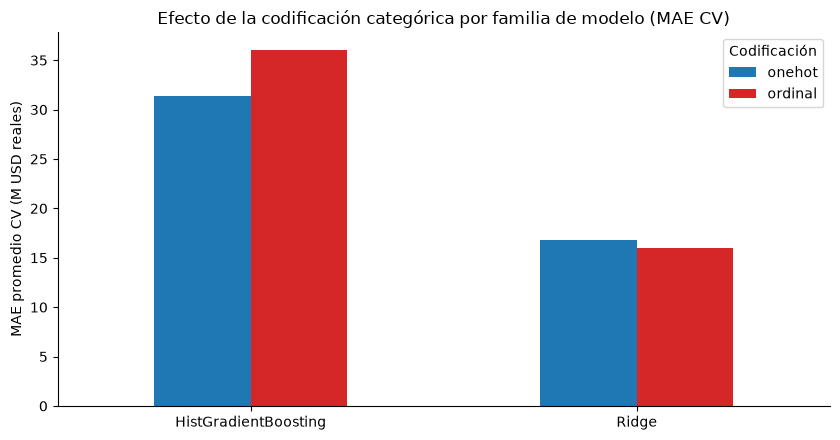

In [4]:
X_tr = train_df[COLUMNAS_MODELO]
y_tr = train_df[OBJETIVO]
tscv = TimeSeriesSplit(n_splits=5)

filas_cod = []
for cod in ["onehot", "ordinal"]:
    prep = construir_preparacion(codificacion=cod)
    n_cols = prep.fit_transform(X_tr).shape[1]
    for nombre_mod, mod in [
        ("Ridge", Ridge(alpha=1.0)),
        ("HistGradientBoosting", HistGradientBoostingRegressor(random_state=42)),
    ]:
        scores = -cross_val_score(
            Pipeline([("p", construir_preparacion(codificacion=cod)), ("m", mod)]),
            X_tr,
            y_tr,
            cv=tscv,
            scoring="neg_mean_absolute_error",
        )
        filas_cod.append({
            "codificacion": cod,
            "columnas_resultantes": n_cols,
            "modelo": nombre_mod,
            "mae_cv_promedio": round(float(scores.mean()), 4),
            "mae_cv_std": round(float(scores.std()), 4),
        })

df_cod = pd.DataFrame(filas_cod)
display(df_cod)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
pivot_cod = df_cod.pivot(index="modelo", columns="codificacion", values="mae_cv_promedio")
pivot_cod.plot(kind="bar", ax=ax, color=["#1f77b4", "#d62728"], rot=0)
ax.set_title("Efecto de la codificación categórica por familia de modelo (MAE CV)")
ax.set_ylabel("MAE promedio CV (M USD reales)")
ax.set_xlabel("")
ax.legend(title="Codificación")
plt.tight_layout()
fig.savefig(FIG_DIR / "02_codificacion_categoricas.png", dpi=180, bbox_inches="tight")
plt.show()

**Decisión para el pipeline común (`src/pipeline.py`):**  
`OneHotEncoder(handle_unknown="ignore", sparse_output=False)` evita introducir relaciones ordinales falsas entre códigos CIIU (`001` a `046`) para los modelos lineales y la red neuronal (`MLPRegressor`), y mantiene una dimensionalidad manejable (76 columnas totales en 4,907 filas). Para garantizar una **comparación justa bajo exactamente la misma preparación** (exigencia de la rúbrica), todos los candidatos en los notebooks `03`, `04` y `05` consumen `construir_preparacion("onehot")`.